# CDS303 Final Project 2 — PCA of Seoul Commercial Districts (2025 Q1)

**Research question:** What common patterns of floating population and estimated sales characterize Seoul commercial districts in 2025 Q1?

This notebook reproduces the district-level integration and PCA using the two **already aggregated, 2025 Q1** input CSVs in `data/`. The upstream extraction and aggregation from the original Seoul Open Data Plaza XLSX files are **not** performed here. See `README.md` and `Final_Project_2_Report.md` for the source descriptions and research context.

## 1. Data integration and preprocessing

Each combined row represents one Seoul commercial district in 2025 Q1. Both input tables are restricted to that quarter, so their actual join key is **district code only**, not a separate quarter column. The floating-population CSV contains weekday (Monday–Friday), weekend (Saturday–Sunday), male, and female totals. The estimated-sales CSV contains estimated sales and transaction counts already summed across industries by district. An **inner, one-to-one** join retains districts represented in both sources; unmatched districts are excluded by the join, not by missing-value deletion.

The six numeric activity variables are used for PCA. `district_code` is an identifier and is excluded. No categorical variables are encoded. Check for missing, non-finite, and negative values before applying `log1p` to reduce right skew and `StandardScaler` to put counts and monetary amounts on comparable scales. The weekday/weekend and male/female measures overlap by construction; retaining them emphasizes foot-traffic variation and affects the loadings.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Run the notebook with the project root (containing data/ and figures/) as the working directory.
base = Path.cwd()
foot = pd.read_csv(base / "data/floating_population_2025Q1.csv")
sales = pd.read_csv(base / "data/estimated_sales_2025Q1.csv")
features = ["weekday_foot", "weekend_foot", "male_foot", "female_foot", "sales", "transactions"]

# These CSVs have already been restricted to 2025 Q1 and aggregated by district.
assert foot["district_code"].notna().all() and sales["district_code"].notna().all()
assert foot["district_code"].is_unique and sales["district_code"].is_unique
assert set(features[:4]).issubset(foot.columns)
assert set(features[4:]).issubset(sales.columns)

matched = set(foot["district_code"]) & set(sales["district_code"])
df = foot.merge(sales, on="district_code", how="inner", validate="one_to_one")
assert df["district_code"].is_unique and len(df) == len(matched)
print(f"Input districts: floating population={len(foot):,}, sales={len(sales):,}")
print(f"Matched districts: {len(df):,}; unmatched in supplied CSVs: "
      f"floating population={len(foot)-len(df):,}, sales={len(sales)-len(df):,}")
display(df[features].describe().round(2))

Input districts: floating population=1,572, sales=1,572
Matched districts: 1,572; unmatched in supplied CSVs: floating population=0, sales=0


,weekday_foot,weekend_foot,male_foot,female_foot,sales,transactions
count,1572.00,1572.00,1572.00,1572.00,1.572000e+03,1572.00
mean,606055.97,237340.86,400969.87,442426.87,1.423290e+10,456774.47
std,653093.21,245867.97,431616.17,464841.72,4.785801e+10,1150557.55
min,0.00,0.00,8.00,0.00,4.614790e+05,3.00
25%,177647.75,68199.50,117025.75,128305.25,9.806628e+08,32258.75
50%,421060.00,162805.50,276898.00,301797.00,3.107342e+09,137189.50
75%,835837.75,332444.25,552585.50,614038.75,9.990925e+09,411033.00
max,6358228.00,1819436.00,4304865.00,3968051.00,1.041942e+12,17634406.00


In [2]:
# Validate PCA inputs; do not silently drop rows or impute without a stated rule.
missing = df[features].isna().sum()
print("Missing values by variable:")
display(missing.to_frame("missing_count"))
assert missing.sum() == 0, "Missing PCA inputs require an explicit handling decision."
assert np.isfinite(df[features].to_numpy(dtype=float)).all(), "Non-finite PCA input detected."
assert (df[features] >= 0).all().all(), "log1p requires nonnegative values here."

# A deterministic full PCA: no randomized solver is used.
X_log = np.log1p(df[features])
X = StandardScaler().fit_transform(X_log)
pca = PCA(n_components=None, svd_solver="full")
scores = pca.fit_transform(X)
variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)
loadings = pd.DataFrame(pca.components_.T, index=features,
                        columns=[f"PC{i}" for i in range(1, len(features) + 1)])

# Retain the smallest number of PCs reaching the chosen 80% cumulative-variance threshold.
threshold = 0.80
n_retained = int(np.searchsorted(cumulative_variance, threshold) + 1)
print("Explained variance ratio by component:")
display(pd.DataFrame({"component": loadings.columns,
                      "explained_variance_ratio": variance,
                      "cumulative_explained_variance": cumulative_variance}))
print(f"Retained components: {n_retained} (first to reach {threshold:.0%} cumulative variance)")
print("Eigenvector coefficients for retained PCs (often called loadings in Demo 6):")
display(loadings.iloc[:, :n_retained].round(3))

Missing values by variable:


,missing_count
weekday_foot,0
weekend_foot,0
male_foot,0
female_foot,0
sales,0
transactions,0


Explained variance ratio by component:


,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.764722,0.764722
1,PC2,0.222707,0.987429
2,PC3,0.009420,0.996850
3,PC4,0.002043,0.998893
4,PC5,0.001061,0.999954
5,PC6,0.000046,1.000000


Retained components: 2 (first to reach 80% cumulative variance)
Eigenvector coefficients for retained PCs (often called loadings in Demo 6):


,PC1,PC2
weekday_foot,0.452,-0.208
weekend_foot,0.448,-0.229
male_foot,0.453,-0.205
female_foot,0.450,-0.222
sales,0.297,0.653
transactions,0.314,0.622


## 2. Component selection

We use **80% cumulative explained variance as an analysis choice**, not as a professor-mandated threshold. We retain the smallest number of components reaching that threshold, and examine the scree plot to ensure that this choice is sensible. The variance ratios are computed for **all six components**. The arrows in the biplot are based on PCA eigenvector coefficients (`components_`), as in Demo 6; these are not variance-scaled correlation loadings.

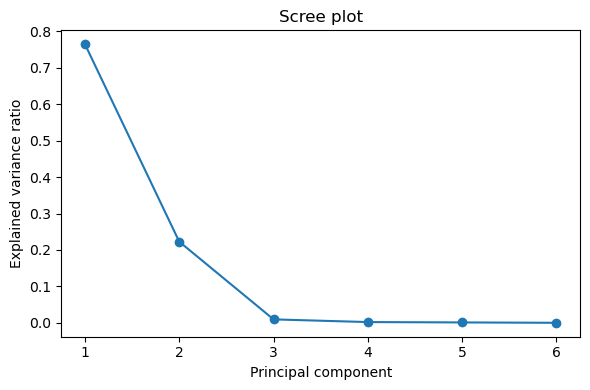

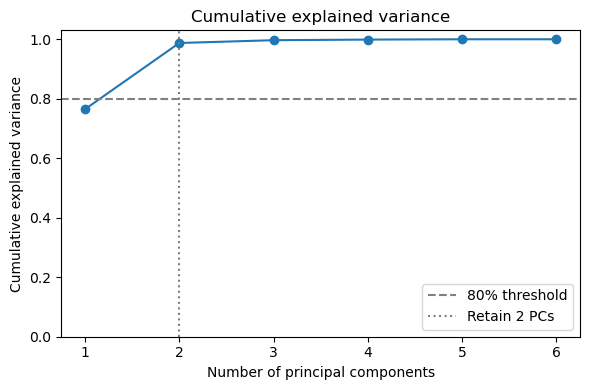

In [3]:
# Save reproducible figures as well as displaying them in the notebook.
figure_dir = base / "figures"
figure_dir.mkdir(exist_ok=True)
pcs = np.arange(1, len(variance) + 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(pcs, variance, marker="o")
ax.set(xlabel="Principal component", ylabel="Explained variance ratio", title="Scree plot", xticks=pcs)
fig.tight_layout()
fig.savefig(figure_dir / "scree.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(pcs, cumulative_variance, marker="o")
ax.axhline(threshold, color="gray", linestyle="--", label=f"{threshold:.0%} threshold")
ax.axvline(n_retained, color="gray", linestyle=":", label=f"Retain {n_retained} PCs")
ax.set(xlabel="Number of principal components", ylabel="Cumulative explained variance",
       title="Cumulative explained variance", xticks=pcs, ylim=(0, 1.03))
ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "cumulative.png", dpi=160)
plt.show()

## 3. PC1–PC2 biplot

The scatter shows district scores on PC1 and PC2. Red arrows show the **directions** of the original standardized-log variables in the PC1–PC2 coefficient plane. Their lengths are multiplied by a common factor solely for display, so **do not read the arrow lengths against the score-axis units**. Because the four floating-population directions nearly coincide, **only the text labels are offset and linked to the unchanged arrow tips** to keep all six names legible. This projection is exploratory and does not establish clusters.


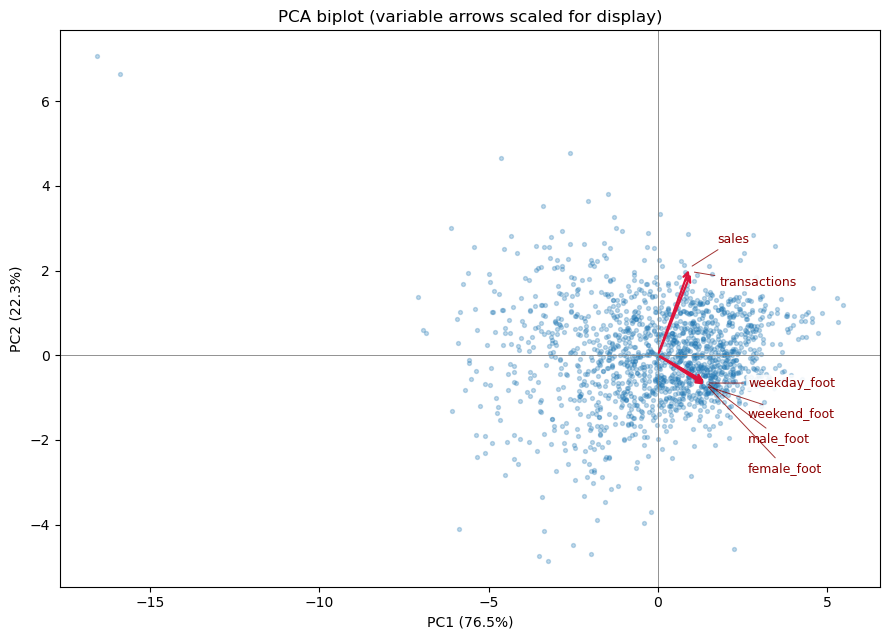

In [4]:
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(scores[:, 0], scores[:, 1], s=8, alpha=0.28)
arrow_scale = max(np.percentile(np.abs(scores[:, 0]), 95),
                  np.percentile(np.abs(scores[:, 1]), 95)) * 0.75

# The four foot-traffic vectors nearly overlap in the PC1-PC2 plane.
# Move ONLY their text labels; preserve all PCA arrow endpoints and directions.
label_offsets = {
    "weekday_foot": (30, 0),
    "weekend_foot": (30, -20),
    "male_foot": (30, -40),
    "female_foot": (30, -60),
    "sales": (20, 20),
    "transactions": (20, -8),
}
for i, name in enumerate(features):
    x_arrow = pca.components_[0, i] * arrow_scale
    y_arrow = pca.components_[1, i] * arrow_scale
    ax.annotate("", xy=(x_arrow, y_arrow), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": "crimson", "lw": 1.6})
    ax.annotate(name, xy=(x_arrow, y_arrow), xycoords="data",
                xytext=label_offsets[name], textcoords="offset points",
                fontsize=9, color="darkred", va="center", ha="left",
                arrowprops={"arrowstyle": "-", "color": "darkred", "lw": 0.7, "alpha": 0.8},
                bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.88},
                annotation_clip=False)
ax.axhline(0, color="gray", linewidth=0.6)
ax.axvline(0, color="gray", linewidth=0.6)
ax.set(xlabel=f"PC1 ({variance[0]:.1%})", ylabel=f"PC2 ({variance[1]:.1%})",
       title="PCA biplot (variable arrows scaled for display)")
fig.tight_layout()
fig.savefig(figure_dir / "biplot.png", dpi=160, bbox_inches="tight")
plt.show()


## 4. Interpretation and limitations

**PC1** has positive coefficients on all six variables, especially the four floating-population measures. It primarily summarizes the overall magnitude of district activity on the standardized log scale. **PC2** has positive coefficients on estimated sales and transaction counts and negative coefficients on floating-population measures; it represents a relative commercial-activity-versus-footfall contrast, **not** a sales-conversion or business-success metric.

The biplot shows that the four foot-traffic arrows point in similar directions, while the two sales-related arrows also align with one another and differ from foot traffic mainly along PC2. Districts spread across both axes, with some more extreme scores; this does **not** establish discrete clusters. These directions can support exploratory comparisons for Seoul commercial-district analysts and prospective small-business owners, but they do not rank business opportunities or demonstrate that foot traffic causes sales.

The two foot-traffic decompositions overlap, estimated sales are model-based estimates, and districts may differ in size and industry mix. The analysis is limited to 2025 Q1. The choice of variables, `log1p` transform, and standardization affect the PCA results. The original 1,650 population districts include 78 districts not represented in the sales source; those are outside this matched analysis. The supplied population CSV already contains only the 1,572 matched districts, so those 78 are **not** removed by the notebook's join.